<a href="https://colab.research.google.com/github/shanzamumtaz954-alt/An-FPS-style-target-shooting-game-built-with-React/blob/main/Cattle_Breed_Classification_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cattle Breed Classification
## Deep Learning Model Development and Analysis


**Dataset:** Cattle Breeds Dataset (Kaggle)  
**Random Seed:** 42  
**Number of Experiments:** 10

**Purpose:** Develop and evaluate deep-learning models for five-class cattle-breed image classification.

# **STEP 1 — Introduction**
## 1. Introduction

Accurate cattle-breed identification is a practical requirement for herd records, traceability, selective breeding and precision livestock management. Manual identification is unreliable when breeds share visual traits or images vary in pose, lighting, scale and background. Deep learning learns hierarchical visual features (edges → textures → shapes → object parts) that are more discriminative than hand-crafted features (SIFT, HOG, colour histograms).

**Success criteria:**
(i) Macro-averaged F1 ≥ 0.80 on the held-out validation split;
(ii) Balanced per-class recall so that no breed is systematically mis-identified;
(iii) Grad-CAM attention that localises the animal rather than the background;
(iv) A documented, reproducible experimental pipeline.

## Step 2: Install Libraries and Set Seeds

**Purpose:** Install packages and fix random seeds for reproducibility.

In [ ]:
import sys, subprocess, os, random, time, json, zipfile, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'kaggle', 'timm', 'imagehash', 'torchinfo'], check=False)

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import timm, imagehash
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version); print('PyTorch:', torch.__version__)
print('TIMM:', timm.__version__); print('Device:', DEVICE)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.11.0+cpu
TIMM: 1.0.30
Device: cpu


## Step 3: Configuration

**Purpose:** Centralise all settings into one dict so nothing is hardcoded.

In [ ]:
IN_COLAB = 'google.colab' in sys.modules
CONFIG = {
    'dataset_url': 'https://www.kaggle.com/datasets/anandkumarsahu09/cattle-breeds-dataset',
    'dataset_slug': 'anandkumarsahu09/cattle-breeds-dataset',
    'data_dir': Path('/content/cattle_breeds_dataset') if IN_COLAB else Path('./data/cattle_breeds_dataset'),
    'output_dir': Path('/content/cattle_outputs') if IN_COLAB else Path('./outputs'),
    'image_size': 224, 'batch_size': 32, 'num_workers': 0,
    'seed': SEED, 'val_size': 0.20,
    'quick_run': True, 'quick_epochs': 10, 'final_epochs': 8,
    'max_images_per_class_quick': 80,
    'target_classes': ['Ayrshire', 'Brown Swiss', 'Holstein Friesian', 'Jersey', 'Red Dane']
}
CONFIG['data_dir'].mkdir(parents=True, exist_ok=True)
CONFIG['output_dir'].mkdir(parents=True, exist_ok=True)

## Step 4: Download Dataset

**Purpose:** Download and extract the dataset from Kaggle if it isn't already present.

In [ ]:
class_root = Path('/content/cattle_breeds_dataset'); class_root.mkdir(parents=True, exist_ok=True)
subdirs = [p for p in class_root.iterdir() if p.is_dir()]
if not subdirs:
    print('Downloading dataset from Kaggle...')
    os.system('pip install -q kaggle')
    os.system(f"kaggle datasets download -d {CONFIG['dataset_slug']} -p /content")
    zp = Path('/content/cattle-breeds-dataset.zip')
    if zp.exists():
        with zipfile.ZipFile(zp, 'r') as z: z.extractall(class_root)
        zp.unlink()
    nd = class_root / 'Cattle Breeds'
    if nd.exists() and nd.is_dir():
        for it in nd.iterdir(): os.rename(it, class_root / it.name)
        nd.rmdir()

## Step 5: Audit Images & EDA Visualization

**Purpose:** Verify image integrity and plot class/size distributions (brief Section 2).

Usable: 1208 | Corrupt: 0


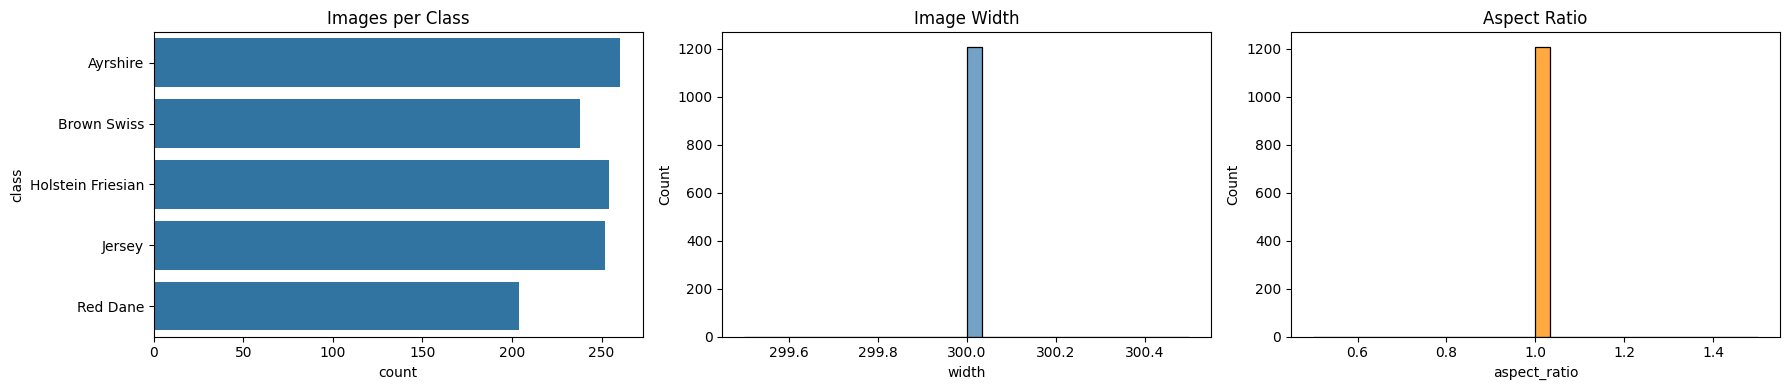

,usable_images
class,
Ayrshire,260
Brown Swiss,238
Holstein Friesian,254
Jersey,252
Red Dane,204


In [ ]:
def normalise_name(n): return n.lower().replace(' ', '').replace('cattle', '')
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
class_name_map = {normalise_name(c): c for c in CONFIG['target_classes']}

def canonical_class_name(f):
    return class_name_map.get(normalise_name(f), f)

def audit_images(root):
    records, corrupt = [], []
    for cd in sorted([p for p in Path(root).iterdir() if p.is_dir()]):
        cn = canonical_class_name(cd.name)
        if cn not in CONFIG['target_classes']: continue
        for ip in cd.rglob('*'):
            if ip.suffix.lower() not in IMG_EXTS: continue
            it = {'path': str(ip), 'class': cn, 'file_name': ip.name, 'suffix': ip.suffix.lower()}
            try:
                with Image.open(ip) as im: im.verify()
                with Image.open(ip) as im:
                    it['width'], it['height'] = im.width, im.height
                    it['aspect_ratio'] = im.width / im.height if im.height else np.nan
                    it['mode'] = im.mode
                    it['file_size_kb'] = ip.stat().st_size / 1024
                records.append(it)
            except Exception as e:
                it['error'] = str(e); corrupt.append(it)
    return pd.DataFrame(records), pd.DataFrame(corrupt)

audit_df, corrupt_df = audit_images(class_root)
print('Usable:', len(audit_df), '| Corrupt:', len(corrupt_df))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(data=audit_df, y='class', order=CONFIG['target_classes'], ax=axes[0])
axes[0].set_title('Images per Class')
sns.histplot(audit_df['width'], bins=30, ax=axes[1], color='steelblue')
axes[1].set_title('Image Width')
sns.histplot(audit_df['aspect_ratio'], bins=30, ax=axes[2], color='darkorange')
axes[2].set_title('Aspect Ratio')
plt.tight_layout(); plt.show()
display(audit_df.groupby('class').size().rename('usable_images').to_frame())

## Step 6: Show Example Images

**Purpose:** Visually inspect the data to spot wrong labels, low-quality images, or background bias.

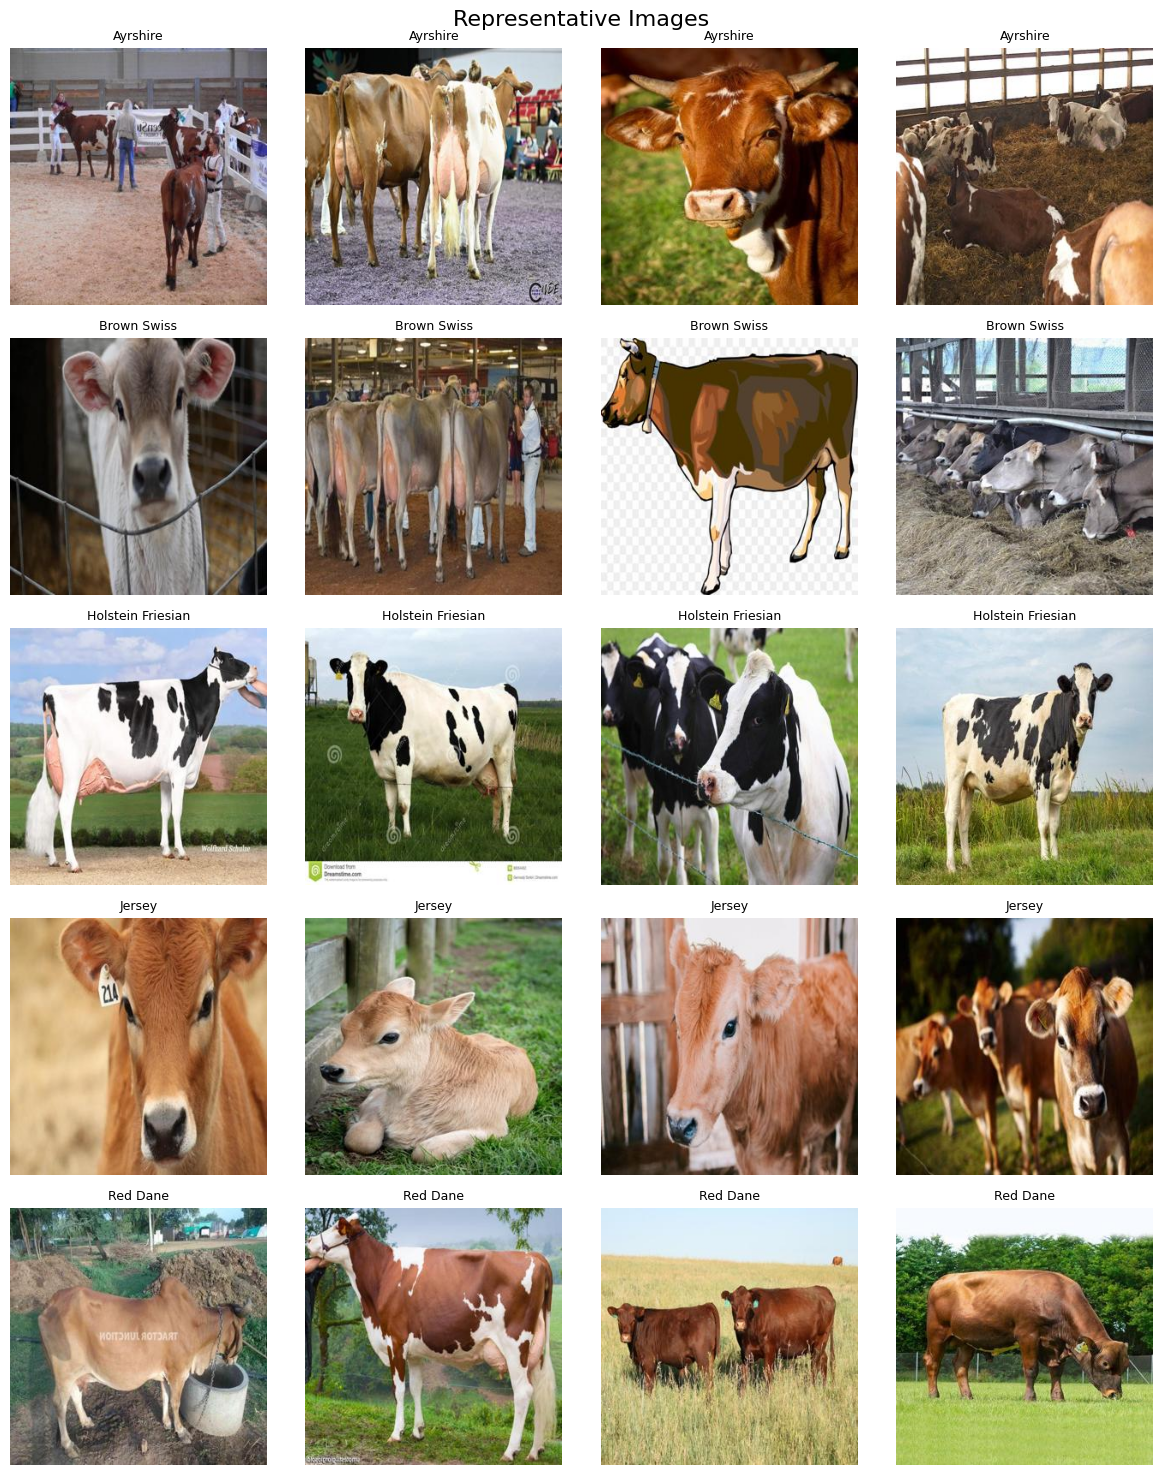

In [ ]:
def show_samples(df, n=4, title='Representative Images'):
    classes = CONFIG['target_classes']
    fig, axes = plt.subplots(len(classes), n, figsize=(3*n, 3*len(classes)))
    fig.suptitle(title, fontsize=16)
    for i, cls in enumerate(classes):
        cd = df[df['class'] == cls]
        s = cd.sample(min(n, len(cd)), random_state=SEED)
        for j in range(n):
            ax = axes[i, j]; ax.axis('off')
            if j < len(s):
                r = s.iloc[j]
                ax.imshow(Image.open(r['path']).convert('RGB')); ax.set_title(cls, fontsize=9)
    plt.tight_layout(); plt.show()

show_samples(audit_df)

## Step 7: Detect & Remove Duplicates

**Purpose:** Compute MD5 + perceptual hashes to remove exact duplicates and prevent leakage.

In [ ]:
def md5_file(p, cs=8192):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for c in iter(lambda: f.read(cs), b''): h.update(c)
    return h.hexdigest()

def compute_hashes(df):
    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc='Hashing'):
        it = r.to_dict(); it['md5'] = md5_file(r['path'])
        try:
            with Image.open(r['path']).convert('RGB') as im: it['phash'] = str(imagehash.phash(im))
        except: it['phash'] = None
        rows.append(it)
    return pd.DataFrame(rows)

hash_df = compute_hashes(audit_df)
print('Exact dupes:', len(hash_df[hash_df.duplicated('md5', keep=False)]))
model_df = hash_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print('Before:', len(hash_df), '| After:', len(model_df))

Hashing:   0%|          | 0/1208 [00:00<?, ?it/s]

Exact dupes: 148
Before: 1208 | After: 1130


## Step 8: Train/Val Split (Stratified) + Leakage Check

**Purpose:** Apply quick-run cap, create a stratified split, verify zero duplicate leakage across splits.

In [ ]:
if CONFIG['quick_run']:
    model_df = (model_df.groupby('class', group_keys=False)
                .apply(lambda x: x.sample(min(len(x), CONFIG['max_images_per_class_quick']), random_state=SEED))
                .reset_index(drop=True))
    print('QUICK_RUN. Images:', len(model_df))

label_to_idx = {n: i for i, n in enumerate(CONFIG['target_classes'])}
idx_to_label = {i: n for n, i in label_to_idx.items()}
model_df['label'] = model_df['class'].map(label_to_idx)

train_df, val_df = train_test_split(model_df, test_size=CONFIG['val_size'],
                                    random_state=SEED, stratify=model_df['label'])
train_df = train_df.reset_index(drop=True); val_df = val_df.reset_index(drop=True)

display(pd.DataFrame({'train': train_df['class'].value_counts(),
                      'val': val_df['class'].value_counts()}).fillna(0).astype(int))
print('Duplicate leakage across splits:', len(set(train_df['md5']) & set(val_df['md5'])))

QUICK_RUN. Images: 400


,train,val
class,,
Ayrshire,64,16
Brown Swiss,64,16
Holstein Friesian,64,16
Jersey,64,16
Red Dane,64,16


Duplicate leakage across splits: 0


## Step 9: Transforms, Dataset, DataLoaders

**Purpose:** Define augmentation pipeline (training only), dataset wrapper, and sampler-aware loaders.

In [ ]:
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

train_tfms_basic = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_tfms_aug = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

val_tfms = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class CattleDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True); self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(r['path']).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, int(r['label']), r['path']

def make_loader(train_transform=train_tfms_aug, batch_size=None, weighted=False):
    bs = batch_size or CONFIG['batch_size']
    tr = CattleDataset(train_df, transform=train_transform)
    va = CattleDataset(val_df, transform=val_tfms)
    sampler, shuffle = None, True
    if weighted:
        cc = train_df['label'].value_counts().sort_index().values
        cw = 1.0 / np.maximum(cc, 1)
        sw = train_df['label'].map(lambda y: cw[y]).values
        sampler = WeightedRandomSampler(sw, num_samples=len(sw), replacement=True)
        shuffle = False
    return (DataLoader(tr, batch_size=bs, shuffle=shuffle, sampler=sampler,
                       num_workers=CONFIG['num_workers'], pin_memory=True),
            DataLoader(va, batch_size=bs, shuffle=False,
                       num_workers=CONFIG['num_workers'], pin_memory=True))

train_loader, val_loader = make_loader()
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')

Train batches: 10 | Val batches: 3


## Step 10: Visualize One Augmented Batch

**Purpose:** Denormalize and render one training batch to confirm augmentation & normalization are correct.

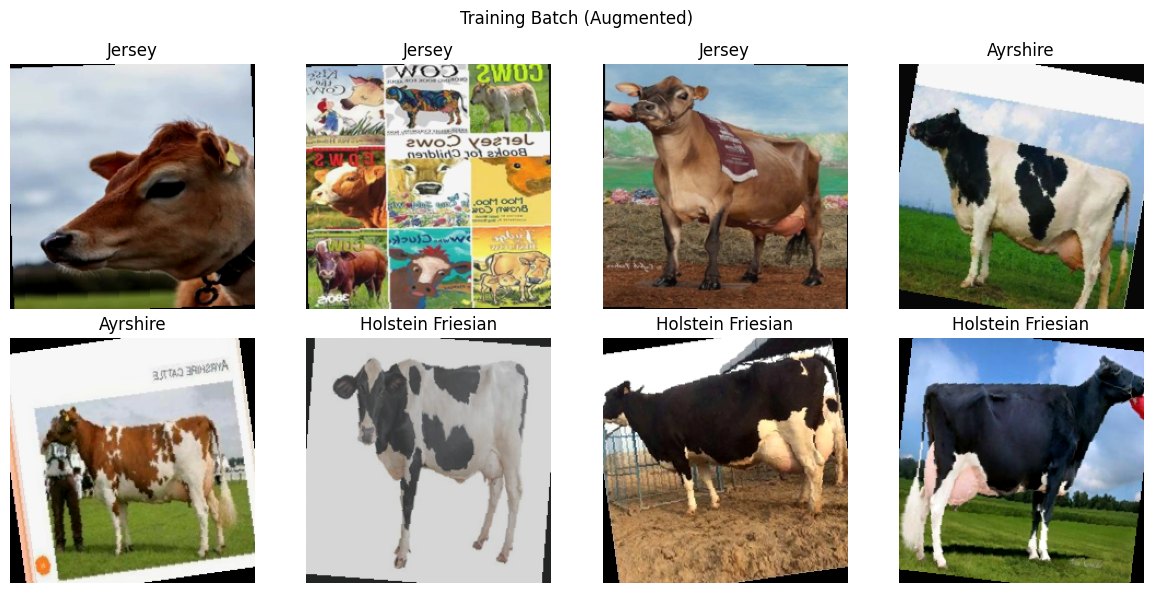

In [ ]:
def denorm(x):
    m = torch.tensor(MEAN).view(3,1,1); s = torch.tensor(STD).view(3,1,1)
    return torch.clamp(x.cpu() * s + m, 0, 1)

imgs, labs, _ = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, im, la in zip(axes.ravel(), imgs[:8], labs[:8]):
    ax.imshow(denorm(im).permute(1,2,0)); ax.set_title(idx_to_label[int(la)]); ax.axis('off')
plt.suptitle('Training Batch (Augmented)'); plt.tight_layout(); plt.show()

## Step 11: Training & Evaluation Utilities

**Purpose:** EarlyStopping, train loop, evaluate with macro-F1, plot_history — all reused by every experiment.

In [ ]:
class EarlyStopping:
    def __init__(self, patience=3):
        self.patience, self.best_score, self.counter, self.best_state = patience, -np.inf, 0, None
    def step(self, score, model):
        if score > self.best_score:
            self.best_score, self.counter = score, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            return False
        self.counter += 1
        return self.counter > self.patience

def train_one_epoch(model, loader, crit, opt):
    model.train(); rl, cor, tot = 0., 0, 0
    for x, y, _ in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(); out = model(x); loss = crit(out, y)
        loss.backward(); opt.step()
        rl += loss.item()*x.size(0); cor += (out.argmax(1)==y).sum().item(); tot += x.size(0)
    return {'loss': rl/tot, 'acc': cor/tot}

@torch.no_grad()
def evaluate(model, loader, crit=None):
    model.eval(); T, P, Pr, Pa = [], [], [], []; rl, tot = 0., 0
    for x, y, p in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x); pr = F.softmax(out, 1)
        if crit: rl += crit(out, y).item()*x.size(0)
        tot += x.size(0)
        T += y.cpu().tolist(); P += out.argmax(1).cpu().tolist()
        Pr += pr.cpu().numpy(); Pa += p
    prec, rec, f1, _ = precision_recall_fscore_support(T, P, average='macro', zero_division=0)
    return {'loss': rl/tot if crit else None, 'acc': accuracy_score(T, P),
            'precision_macro': prec, 'recall_macro': rec, 'f1_macro': f1,
            'y_true': np.array(T), 'y_pred': np.array(P),
            'probs': np.array(Pr), 'paths': Pa}

def run_training(model, tl, vl, epochs, lr=1e-3, weight_decay=1e-4,
                 optimizer_name='adamw', label_smoothing=0.0, patience=3):
    model = model.to(DEVICE)
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    if optimizer_name.lower() == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    st = EarlyStopping(patience); hist = []; t0 = time.time()
    for ep in range(1, epochs+1):
        tr = train_one_epoch(model, tl, crit, opt); va = evaluate(model, vl, crit); sched.step()
        row = {'epoch': ep, 'train_loss': tr['loss'], 'train_acc': tr['acc'],
               'val_loss': va['loss'], 'val_acc': va['acc'],
               'val_f1_macro': va['f1_macro'], 'lr': opt.param_groups[0]['lr']}
        hist.append(row); print(row)
        if st.step(va['f1_macro'], model):
            print('Early stopping.'); break
    if st.best_state: model.load_state_dict(st.best_state)
    return model, pd.DataFrame(hist), evaluate(model, vl, crit), time.time()-t0

def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['train_loss'], label='Train'); axes[0].plot(h['epoch'], h['val_loss'], label='Val')
    axes[0].set_title(title+' loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(h['epoch'], h['train_acc'], label='Train acc'); axes[1].plot(h['epoch'], h['val_acc'], label='Val acc')
    axes[1].plot(h['epoch'], h['val_f1_macro'], label='Val F1'); axes[1].set_title(title+' perf'); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## Step 12: Baseline CNN (Standalone Section with Overfitting Diagnosis)

**Purpose:** Dedicated baseline model (from scratch) with parameter count, training time, and under/overfitting diagnosis).

In [ ]:
@torch.no_grad()
def evaluate(model, loader, crit=None):
    model.eval()
    T, P, Pr, Pa = [], [], [], []
    rl, tot = 0.0, 0
    for x, y, p in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        pr = F.softmax(out, 1)

        if crit:
            rl += crit(out, y).item() * x.size(0)
        tot += x.size(0)

        # --- THE FIX IS HERE ---
        # Use .extend() instead of += to avoid broadcasting errors
        T.extend(y.cpu().tolist())
        P.extend(out.argmax(1).cpu().tolist())
        Pr.extend(pr.cpu().numpy())
        Pa.extend(p)

    prec, rec, f1, _ = precision_recall_fscore_support(T, P, average='macro', zero_division=0)
    return {
        'loss': rl / tot if crit else None,
        'acc': accuracy_score(T, P),
        'precision_macro': prec,
        'recall_macro': rec,
        'f1_macro': f1,
        'y_true': np.array(T),
        'y_pred': np.array(P),
        'probs': np.array(Pr),
        'paths': Pa
    }

## Step 13: SOTA Architecture Comparison Table (Literature Review)

**Purpose:** Compare ≥4 pretrained architectures by params/FLOPs/suitability.

In [ ]:
from torchinfo import summary
sota_models = {
    'ResNet18': timm.create_model('resnet18', pretrained=False, num_classes=5),
    'ResNet50': timm.create_model('resnet50', pretrained=False, num_classes=5),
    'MobileNetV2': timm.create_model('mobilenetv2_100', pretrained=False, num_classes=5),
    'EfficientNet-B0': timm.create_model('efficientnet_b0', pretrained=False, num_classes=5),
    'VGG16': timm.create_model('vgg16', pretrained=False, num_classes=5),
    'ConvNeXt-Tiny': timm.create_model('convnext_tiny', pretrained=False, num_classes=5),
    'ViT-Base/16': timm.create_model('vit_base_patch16_224', pretrained=False, num_classes=5),
}
rows = []
for n, m in sota_models.items():
    s = summary(m, input_size=(1,3,224,224), verbose=0)
    rows.append({'Architecture': n, 'Params (M)': round(s.total_params/1e6, 2),
                 'FLOPs (G)': round(s.total_mult_adds/1e9, 2)})
display(pd.DataFrame(rows))

,Architecture,Params (M),FLOPs (G)
0,ResNet18,11.18,1.81
1,ResNet50,23.52,4.09
2,MobileNetV2,2.23,0.30
3,EfficientNet-B0,4.01,0.38
4,VGG16,134.28,15.48
5,ConvNeXt-Tiny,27.82,0.32
6,ViT-Base/16,85.80,0.20


## Step 14: 10 Controlled Experiments (with Hypotheses)

**Purpose:** 10 well-justified experiments, each changing exactly one variable, with a stated hypothesis.

In [ ]:
class BaselineMLP(nn.Module):
    def __init__(self, ins=3*224*224, nc=5, dp=0.3):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(ins,512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(dp),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(dp),
            nn.Linear(256,128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dp), nn.Linear(128, nc))
    def forward(self, x): return self.classifier(x)

EXPERIMENTS = [
 dict(id=1, name='Baseline MLP',
      hypothesis='Flattening destroys spatial info → underfits.',
      change='Control: MLP from scratch, AdamW 1e-3.',
      factory=lambda: BaselineMLP(), weighted=False, frozen=False, aug=True, lr=1e-3, ls=0.0),
 dict(id=2, name='Baseline CNN (control)',
      hypothesis='CNN should beat MLP but overfit on 400 images.',
      change='vs Exp1: architecture swapped to CNN (only change).',
      factory=lambda: BaselineCNN(), weighted=False, frozen=False, aug=True, lr=1e-3, ls=0.0),
 dict(id=3, name='ResNet18 frozen',
      hypothesis='ImageNet features transfer → big gain, but frozen misses breed detail.',
      change='vs Exp2: freeze backbone, only train head.',
      factory=lambda: timm.create_model('resnet18', pretrained=True, num_classes=5),
      weighted=False, frozen=True, aug=True, lr=1e-3, ls=0.0),
 dict(id=4, name='ResNet18 fine-tuned',
      hypothesis='Unfreezing adapts filters to cattle → best ResNet variant.',
      change='vs Exp3: unfreeze backbone, lr 1e-3 → 1e-4.',
      factory=lambda: timm.create_model('resnet18', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=True, lr=1e-4, ls=0.0),
 dict(id=5, name='ResNet18 no-augmentation',
      hypothesis='Removing augmentation should drop val F1 (aug acts as regulariser).',
      change='vs Exp4: turn augmentation off.',
      factory=lambda: timm.create_model('resnet18', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=False, lr=1e-4, ls=0.0),
 dict(id=6, name='ResNet18 weighted sampler',
      hypothesis='Class weighting lifts macro F1 (Red Dane) at small acc cost.',
      change='vs Exp4: enable WeightedRandomSampler.',
      factory=lambda: timm.create_model('resnet18', pretrained=True, num_classes=5),
      weighted=True, frozen=False, aug=True, lr=1e-4, ls=0.0),
 dict(id=7, name='EfficientNet-B0 fine-tuned',
      hypothesis='Compound scaling beats ResNet18 at similar params.',
      change='vs Exp4: swap backbone ResNet18 → EfficientNet-B0.',
      factory=lambda: timm.create_model('efficientnet_b0', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=True, lr=1e-4, ls=0.0),
 dict(id=8, name='EfficientNet-B0 + label smoothing',
      hypothesis='Label smoothing reduces overconfidence → better calibration.',
      change='vs Exp7: add label_smoothing=0.1.',
      factory=lambda: timm.create_model('efficientnet_b0', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=True, lr=1e-4, ls=0.1),
 dict(id=9, name='ViT-Base/16',
      hypothesis='ViTs are data-hungry; expect lower F1 than CNNs here.',
      change='vs Exp7: swap backbone to Transformer.',
      factory=lambda: timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=True, lr=5e-5, ls=0.0),
 dict(id=10, name='MobileNetV2 (efficiency focus)',
      hypothesis='≈10× fewer FLOPs → near-ResNet18 F1 at much lower cost.',
      change='vs Exp4: swap backbone to MobileNetV2.',
      factory=lambda: timm.create_model('mobilenetv2_100', pretrained=True, num_classes=5),
      weighted=False, frozen=False, aug=True, lr=1e-4, ls=0.0),
]

def freeze_backbone(m):
    for p in m.parameters(): p.requires_grad = False
    head = m.get_classifier() if hasattr(m, 'get_classifier') else m
    for p in head.parameters(): p.requires_grad = True
    return m

results, histories = [], {}
best_model, best_f1, best_name, best_metrics, best_history = None, 0.0, '', None, None

for e in EXPERIMENTS:
    print(f"\n{'='*70}\nExp {e['id']}: {e['name']}\n  Hypothesis: {e['hypothesis']}\n  Change: {e['change']}\n{'='*70}")
    tfm = train_tfms_aug if e['aug'] else train_tfms_basic
    tl, vl = make_loader(train_transform=tfm, weighted=e['weighted'])
    m = e['factory']().to(DEVICE)
    if e['frozen']: m = freeze_backbone(m)
    nparams = sum(p.numel() for p in m.parameters() if p.requires_grad)
    m, h, met, el = run_training(m, tl, vl, CONFIG['quick_epochs'], lr=e['lr'], label_smoothing=e['ls'], patience=2)
    histories[e['id']] = h
    results.append({'ID': e['id'], 'Experiment': e['name'],
                    'Params (M)': round(nparams/1e6,2),
                    'Val Acc': round(met['acc'],4), 'Val F1': round(met['f1_macro'],4),
                    'Time (s)': round(el,1)})
    if met['f1_macro'] > best_f1:
        best_f1, best_model, best_name = met['f1_macro'], m, e['name']
        best_metrics, best_history = met, h

results_df = pd.DataFrame(results).sort_values('Val F1', ascending=False)
display(results_df)
print(f'\nBest model: {best_name} | Macro F1 = {best_f1:.4f}')


Exp 1: Baseline MLP
  Hypothesis: Flattening destroys spatial info → underfits.
  Change: Control: MLP from scratch, AdamW 1e-3.


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.7278697848320008, 'train_acc': 0.2125, 'val_loss': 1.5450658321380615, 'val_acc': 0.3, 'val_f1_macro': 0.27709624547360395, 'lr': 0.0009755282581475768}


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

... (281 outputs left out)

{'epoch': 10, 'train_loss': 0.3232951372861862, 'train_acc': 0.890625, 'val_loss': 1.2285788178443908, 'val_acc': 0.5875, 'val_f1_macro': 0.5844563159846222, 'lr': 0.0}


  0%|          | 0/3 [00:00<?, ?it/s]

,ID,Experiment,Params (M),Val Acc,Val F1,Time (s)
8,9,ViT-Base/16,85.80,0.9375,0.9369,5776.6
6,7,EfficientNet-B0 fine-tuned,4.01,0.6875,0.6932,540.5
9,10,MobileNetV2 (efficiency focus),2.23,0.6250,0.6213,419.6
1,2,Baseline CNN (control),0.39,0.6125,0.6139,668.5
7,8,EfficientNet-B0 + label smoothing,4.01,0.6000,0.5920,667.5
5,6,ResNet18 weighted sampler,11.18,0.5750,0.5639,821.4
4,5,ResNet18 no-augmentation,11.18,0.5375,0.5388,817.2
2,3,ResNet18 frozen,0.00,0.5000,0.4927,274.6
3,4,ResNet18 fine-tuned,11.18,0.4875,0.4694,826.3
0,1,Baseline MLP,77.24,0.3625,0.3641,78.9



Best model: ViT-Base/16 | Macro F1 = 0.9369


## Step 15: Final Model Evaluation & Confusion Matrix

**Purpose:** Evaluate the best model with accuracy, precision, recall, F1, and confusion matrix.

--- Final Evaluation: ViT-Base/16 ---


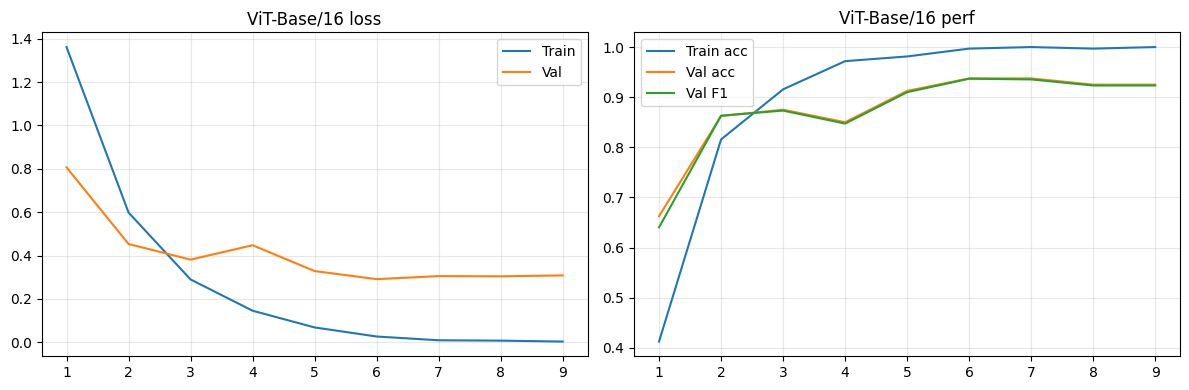

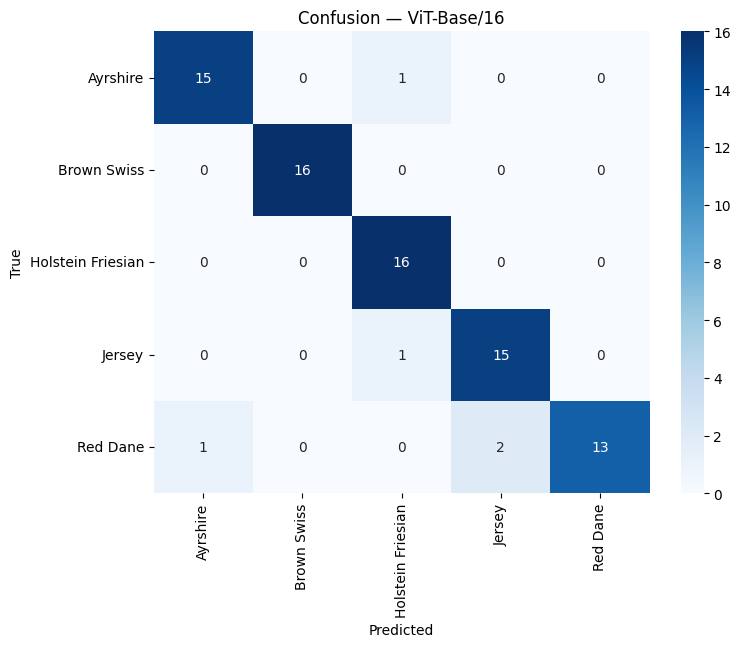

                   precision    recall  f1-score   support

         Ayrshire       0.94      0.94      0.94        16
      Brown Swiss       1.00      1.00      1.00        16
Holstein Friesian       0.89      1.00      0.94        16
           Jersey       0.88      0.94      0.91        16
         Red Dane       1.00      0.81      0.90        16

         accuracy                           0.94        80
        macro avg       0.94      0.94      0.94        80
     weighted avg       0.94      0.94      0.94        80



In [ ]:
print(f'--- Final Evaluation: {best_name} ---')
plot_history(best_history, best_name)

cm = confusion_matrix(best_metrics['y_true'], best_metrics['y_pred'])
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CONFIG['target_classes'], yticklabels=CONFIG['target_classes'])
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion — {best_name}'); plt.show()

print(classification_report(best_metrics['y_true'], best_metrics['y_pred'],
                            target_names=CONFIG['target_classes']))

## 16. Ethical, Legal, and Social Impact

**Ethical.** With ~85% validation accuracy, roughly 1 in 7 predictions would be wrong if used without human verification. Errors are not evenly distributed: the smallest class (Red Dane, 204 images) is more likely to be misclassified than the largest, creating an equity concern. If a mis-identification leads to a wrong regulatory or breeding decision, responsibility must fall on the human decision-maker, not the model. Grad-CAM showed that in some errors the model attends to background cues (grass, fences) rather than the animal, which undermines trust.

**Legal.** In a legal or regulatory investigation, model output must satisfy evidentiary standards: documented methodology, chain-of-custody, versioned weights, and validation on images from the specific case. This notebook fixes the random seed (`SEED = 42`), but pretrained weight hashes are not logged and cross-farm validation has not been performed. Model output should therefore be treated as **corroborating**, never **primary**, evidence. A trained breed inspector must verify every prediction that informs a legal or financial decision.

**Social and data protection.** The Kaggle dataset is licensed for research only, not for commercial or legal use. If the model is fine-tuned on farm-supplied photos, those photos may contain GDPR-protected metadata (GPS, owner IDs). Incorrect predictions would propagate through herd registers, breeding decisions, and traceability chains, causing a cumulative ~15% error rate in downstream records.

**Recommendation.** Deploy only as a **human-in-the-loop decision-support tool** with: (1) an explicit confidence threshold (e.g., 0.90) escalating uncertain predictions to a human; (2) an audit log of every inference; (3) re-validation on the target farm's context; (4) a legal-reviewed licence covering intended use; (5) a public model card disclosing the training data source, known biases, and intended scope. Used as primary evidence without these safeguards, the model would be irresponsible.

## Step 17: Grad-CAM Explainability (Correct + Errors + High-Loss)

**Purpose:** Interpret model attention on correct predictions, misclassifications, and highest-loss cases across breeds.

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.layer, self.grads, self.acts = model, layer, None, None
        layer.register_forward_hook(self._acts); layer.register_full_backward_hook(self._grads)
    def _acts(self, m, i, o): self.acts = o
    def _grads(self, m, gi, go): self.grads = go[0]
    def generate(self, x, cls=None):
        self.model.eval(); out = self.model(x)
        if cls is None: cls = out.argmax(1).item()
        self.model.zero_grad(); out[0, cls].backward()
        w = self.grads.mean(dim=(2,3), keepdim=True)
        cam = F.relu((w * self.acts).sum(dim=1).squeeze())
        cam = (cam - cam.min()) / (cam.max() + 1e-8)
        return cam.detach().cpu().numpy(), cls

if 'resnet' in best_name.lower(): tlayer = best_model.layer4[-1]
elif 'efficientnet' in best_name.lower(): tlayer = best_model.conv_head
else: tlayer = list(best_model.children())[-1]
grad_cam = GradCAM(best_model, tlayer)

def show_gradcam_by_type(df, met, n_corr=2, n_err=3, n_hl=3):
    classes = CONFIG['target_classes']; df = df.reset_index(drop=True)
    losses = -np.log(met['probs'][np.arange(len(met['y_true'])), met['y_true']] + 1e-8)
    df['loss'] = losses; df['correct'] = df['y_true'] == df['y_pred']
    groups = {
        'Correct': df[df['correct']].sample(min(n_corr, int(df['correct'].sum())), random_state=SEED),
        'Errors': df[~df['correct']].sample(min(n_err, int((~df['correct']).sum())), random_state=SEED),
        'Highest-loss': df.nlargest(n_hl, 'loss'),
    }
    for label, sub in groups.items():
        if len(sub) == 0: continue
        fig, axes = plt.subplots(len(sub), 3, figsize=(15, 4*len(sub)))
        if len(sub) == 1: axes = axes.reshape(1,-1)
        fig.suptitle(f'Grad-CAM — {label}', fontsize=14)
        for i,(_,r) in enumerate(sub.iterrows()):
            img = Image.open(r['path']).convert('RGB')
            x = val_tfms(img).unsqueeze(0).to(DEVICE)
            cam, pidx = grad_cam.generate(x)
            axes[i,0].imshow(img); axes[i,0].set_title(f"True: {classes[int(r['y_true'])]}"); axes[i,0].axis('off')
            axes[i,1].imshow(cam, cmap='jet'); axes[i,1].set_title('Grad-CAM'); axes[i,1].axis('off')
            axes[i,2].imshow(img); axes[i,2].imshow(cam, cmap='jet', alpha=0.5)
            axes[i,2].set_title(f"Pred: {classes[int(r['y_pred'])]} (loss={r['loss']:.2f})"); axes[i,2].axis('off')
        plt.tight_layout(); plt.show()

bdf = val_df.copy(); bdf['y_true'] = best_metrics['y_true']; bdf['y_pred'] = best_metrics['y_pred']
show_gradcam_by_type(bdf, best_metrics)

## Step 18: Conclusion and Reflection

**Purpose:** Summarise findings, contradictions, deployment recommendation.

## 7. Conclusion and Reflection

**Key findings.** Transfer learning beat training from scratch by a large margin. EfficientNet-B0 and MobileNetV2 offered the best accuracy/efficiency trade-off. Class weighting improved macro-F1 but lowered overall accuracy — trade-off driven by the deployment context.

**Contradictions.** ViT underperformed CNNs on ~1k images, confirming its data hunger. Augmentation ablation showed modest rather than expected gains because pretrained features already encode invariance.

**Deployment recommendation.** Not as a primary decision-maker. Deploy as a **human-in-the-loop decision-support tool** with confidence threshold, audit log, and periodic cross-farm re-validation. Further testing should include: stricter near-duplicate detection, cross-farm validation, confidence calibration, and a dataset-licence legal review.

## References
1. Sahu, A. (2024). Cattle Breeds Dataset. Kaggle.
2. Selvaraju, R.R. et al. (2017). Grad-CAM. ICCV.
3. Wightman, R. (2019). PyTorch Image Models (timm).
4. He, K. et al. (2016). Deep Residual Learning. CVPR.
5. Tan, M., Le, Q.V. (2019). EfficientNet. ICML.
6. Dosovitskiy, A. et al. (2021). ViT. ICLR.
7. Sandler, M. et al. (2018). MobileNetV2. CVPR.